## 1. Setup

### 1.1 Load, scope and split

The same steps as `01_scoping_eda.ipynb` (sections 2 and 3.1), without the checks and explanations. The seed and the
row order are the same, so train, validation and test contain the same patients the EDA decisions were based on.


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.base import BaseEstimator
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier



DATA_DIR = Path("../data/raw")  # notebook runs from notebooks/
DIAG_COLS = ["diag_1", "diag_2", "diag_3"]

# Discharged as expired (11, 19, 20, 21) or to hospice (13, 14)
EXCLUDED_DISCHARGE = [11, 13, 14, 19, 20, 21]


def icd9_group(code: str | float) -> str:
    """Map an ICD-9 code to one of the 9 disease groups of Strack et al. (2014)."""
    if pd.isna(code):
        return "Missing"
    if code[0] in "VE":  # supplementary (V) and external-cause (E) codes
        return "Other"
    value = float(code)
    chapter = int(value)  # integer part: "786.05" -> 786
    if 390 <= value < 460 or chapter == 785:
        return "Circulatory"
    if 460 <= value < 520 or chapter == 786:
        return "Respiratory"
    if 520 <= value < 580 or chapter == 787:
        return "Digestive"
    if chapter == 250:
        return "Diabetes"
    if 800 <= value < 1000:
        return "Injury"
    if 710 <= value < 740:
        return "Musculoskeletal"
    if 580 <= value < 630 or chapter == 788:
        return "Genitourinary"
    if 140 <= value < 240:
        return "Neoplasms"
    return "Other"


df_raw = pd.read_csv(
    DATA_DIR / "diabetic_data.csv",
    na_values=["?"],        # the dataset's only missing-value token
    keep_default_na=False,  # keep "None" (test not measured) as a category
    low_memory=False,
)

# Scoping: first encounter per patient, no death / hospice, known gender
df = df_raw.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
df = df[~df["discharge_disposition_id"].isin(EXCLUDED_DISCHARGE)]
df = df[df["gender"] != "Unknown/Invalid"].reset_index(drop=True)

# 1 = readmitted within 30 days; ">30" and "NO" both become 0
df["target"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns="readmitted")

# Empty code beyond number_diagnoses = no such diagnosis -> "Absent" instead of "Missing"
for position, col in enumerate(DIAG_COLS, start=1):
    groups = df[col].map(icd9_group)
    absent = df[col].isna() & (df["number_diagnoses"] < position)
    df[f"{col}_group"] = groups.mask(absent, "Absent")

# Same seed and order as the EDA, so the three parts contain the same patients
df_full_train, df_test = train_test_split(df, test_size=0.2, stratify=df["target"], random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, stratify=df_full_train["target"], random_state=1
)

for name, part in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"{name}: {len(part)} rows, positive rate {part['target'].mean():.2%}")


train: 41982 rows, positive rate 8.97%
val: 13994 rows, positive rate 8.98%
test: 13994 rows, positive rate 8.97%


## 2. Data preparation

### 2.1 Fixed cleaning rules

The decisions from section 3.6 of the EDA. A function, so that train, validation and later the service all get exactly the same
treatment. These rules are fixed in advance and read nothing from the data, so they cannot leak information from validation.


In [2]:
DROP_COLS = [
    "encounter_id", "patient_nbr",  # identifiers
    "examide", "citoglipton", "glimepiride-pioglitazone", "metformin-pioglitazone",  # one value in train
    "weight", "payer_code",  # mostly missing
    *DIAG_COLS,  # replaced by the _group columns
]

# Codes that mean "not available / NULL / not mapped" in IDS_mapping.csv
UNKNOWN_CODES = {
    "admission_type_id": [5, 6, 8],
    "discharge_disposition_id": [18, 25, 26],
    "admission_source_id": [9, 15, 17, 20, 21],
}


def clean(data: pd.DataFrame) -> pd.DataFrame:
    """Apply the fixed rules of the 3.6 decisions table. Nothing here is learned from the data."""
    data = data.drop(columns=DROP_COLS)
    data[["race", "medical_specialty"]] = data[["race", "medical_specialty"]].fillna("Missing")
    for col, codes in UNKNOWN_CODES.items():
        # Codes become text, so a model cannot treat them as quantities
        data[col] = data[col].astype(str).mask(data[col].isin(codes), "Unknown")
    return data


# New names, so df_train and df_val stay intact and this cell can be re-run
train_clean = clean(df_train)
val_clean = clean(df_val)

print(train_clean.shape, val_clean.shape)
print("missing values left:", train_clean.isna().sum().sum(), val_clean.isna().sum().sum())
train_clean[list(UNKNOWN_CODES)].eq("Unknown").sum()


(41982, 42) (13994, 42)
missing values left: 0 0


admission_type_id           4716
discharge_disposition_id    1960
admission_source_id         3035
dtype: int64

### 2.2 Merge rare categories

Categories with under 100 training patients become "Other", in `medical_specialty` and the three ID columns, because rates
measured on tiny groups are unreliable. Unlike 2.1, this step learns from the data: the lists of kept categories come from
the training set only, and the same lists are applied to validation and later saved for the service.


In [3]:
MIN_PATIENTS = 100
RARE_COLS = ["medical_specialty", *UNKNOWN_CODES]  # unpacking a dict gives its keys


def fit_kept_categories(train: pd.DataFrame) -> dict[str, list[str]]:
    """Return, per column, the categories with at least MIN_PATIENTS patients in the training data."""
    kept = {}
    for col in RARE_COLS:
        counts = train[col].value_counts()
        kept[col] = counts[counts >= MIN_PATIENTS].index.tolist()
    return kept


def merge_rare(data: pd.DataFrame, kept: dict[str, list[str]]) -> pd.DataFrame:
    """Replace every category outside the kept lists with "Other"."""
    data = data.copy()  # leave the caller's DataFrame untouched
    for col, categories in kept.items():
        # .where keeps the value when the condition is true, otherwise writes "Other"
        data[col] = data[col].where(data[col].isin(categories), "Other")
    return data


kept_categories = fit_kept_categories(train_clean)
train_prep = merge_rare(train_clean, kept_categories)
val_prep = merge_rare(val_clean, kept_categories)

pd.DataFrame({
    "before": train_clean[RARE_COLS].nunique(),
    "after": train_prep[RARE_COLS].nunique(),
    "train_to_other": train_prep[RARE_COLS].eq("Other").sum(),
    "val_to_other": val_prep[RARE_COLS].eq("Other").sum(),
})


,before,after,train_to_other,val_to_other
medical_specialty,66,22,916,320
admission_type_id,6,5,14,4
discharge_disposition_id,20,11,151,52
admission_source_id,15,8,100,35


### 2.3 Feature sets and target

Two lists of inputs go to modelling: all columns, and a reduced list without the 11 near-constant drugs and `gender`. The
reduced list goes into the service unless it lowers the validation AUC by more than 0.005 compared with all columns.


In [4]:
# 99%+ of train patients on one value, plus gender (MI 0): removed in the reduced list
LOW_SIGNAL_COLS = [
    "acetohexamide", "metformin-rosiglitazone", "troglitazone", "glipizide-metformin",
    "miglitol", "tolbutamide", "tolazamide", "chlorpropamide", "acarbose", "nateglinide",
    "glyburide-metformin", "gender",
]

FEATURES_ALL = [c for c in train_prep.columns if c != "target"]
FEATURES_REDUCED = [c for c in FEATURES_ALL if c not in LOW_SIGNAL_COLS]

# The 6 skewed counts: log1p is tested against plain values on the logistic regression only
LOG_COLS = [
    "time_in_hospital", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient",
]

y_train = train_prep["target"].to_numpy()
y_val = val_prep["target"].to_numpy()

# Catches a typo in a column name, which the list comprehension above would silently ignore
assert set(LOW_SIGNAL_COLS) <= set(FEATURES_ALL)
assert set(LOG_COLS) <= set(FEATURES_ALL)

print(f"all: {len(FEATURES_ALL)} inputs, reduced: {len(FEATURES_REDUCED)} inputs")
print(f"y_train mean {y_train.mean():.4f}, y_val mean {y_val.mean():.4f}")


all: 41 inputs, reduced: 29 inputs
y_train mean 0.0897, y_val mean 0.0898


## 3. Models

### 3.1 Logistic regression baseline

The simplest model sets the score the others must beat. Its inputs are the plain counts or `log1p` of the 6 skewed counts:
a linear model feels a value of 10 much more strongly than a 1, so compressing long tails can help it. Both use all columns.
The regularisation strength `C` is then tuned on the version that wins.


In [5]:
def to_dicts(data: pd.DataFrame, features: list[str], log_cols: list[str] | None = None) -> list[dict]:
    """Select the features, optionally apply log1p, and return one dict per patient."""
    X = data[features].copy()
    if log_cols:
        X[log_cols] = np.log1p(X[log_cols])
    return X.to_dict(orient="records")


def evaluate_logreg(features: list[str], log_cols: list[str] | None = None, C: float = 1.0) -> dict[str, float]:
    """Fit on train and return the AUC on train and validation."""
    model = make_pipeline(
        DictVectorizer(),  # one-hot encodes the text columns, passes numbers through
        LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=1),
    )
    model.fit(to_dicts(train_prep, features, log_cols), y_train)

    # [:, 1] is the probability of the positive class (readmitted)
    p_train = model.predict_proba(to_dicts(train_prep, features, log_cols))[:, 1]
    p_val = model.predict_proba(to_dicts(val_prep, features, log_cols))[:, 1]
    return {"train_auc": roc_auc_score(y_train, p_train), "val_auc": roc_auc_score(y_val, p_val)}


logreg_results = pd.DataFrame({
    "plain": evaluate_logreg(FEATURES_ALL),
    "log1p": evaluate_logreg(FEATURES_ALL, LOG_COLS),
}).T
logreg_results.round(4)


,train_auc,val_auc
plain,0.6623,0.6510
log1p,0.6622,0.6519


The baseline reaches a validation AUC of 0.651, well above the 0.566 of the best single numeric column (`time_in_hospital`).
The train AUC (0.662) is close, so the model is not overfitting: this is the score the other models have to beat.

`log1p` adds only 0.0009 (0.6519 vs 0.6510). The rule is to keep a transformation only if it adds more than 0.005 validation
AUC, so the plain counts go forward. This also means one less step to reproduce in the service.


#### Regularisation strength

`C` controls how strongly the model's weights are kept small: a small `C` means a strong penalty and a simpler model, a large
`C` a weak penalty. It is tuned on the plain counts before comparing with the tree-based models.


In [6]:
c_results = pd.DataFrame({
    C: evaluate_logreg(FEATURES_ALL, C=C) for C in [0.001, 0.01, 0.1, 0.5, 1, 5, 10]
}).T
c_results.index.name = "C"
c_results.round(4)


,train_auc,val_auc
C,,
0.001,0.6359,0.6285
0.010,0.6559,0.6488
0.100,0.6609,0.6509
0.500,0.6621,0.6511
1.000,0.6623,0.6510
5.000,0.6625,0.6512
10.000,0.6625,0.6510


A very small `C` underfits (validation AUC 0.629 at `C` = 0.001): the penalty keeps the weights too small to use the data.
From `C` = 0.1 to 10 the validation AUC is flat, between 0.6509 and 0.6512: with about 42,000 training patients and
179 encoded columns the model does not overfit, so weakening the penalty changes almost nothing. `C` stays at the default
1.0, since the best value (`C` = 5) is only 0.0002 higher, far below the 0.005 rule. The tuned baseline is a validation AUC
of 0.651.


### 3.2 Decision tree

A single tree, mainly to see how its depth trades underfitting against overfitting before moving on to the ensembles. The
evaluation function is now generic: any scikit-learn model goes through the same encoding and the same AUC on train and
validation. Plain counts, as decided in 3.1.


In [7]:
def evaluate(estimator: BaseEstimator, features: list[str]) -> dict[str, float]:
    """Fit DictVectorizer + estimator on train and return the AUC on train and validation."""
    model = make_pipeline(DictVectorizer(), estimator)
    model.fit(to_dicts(train_prep, features), y_train)
    p_train = model.predict_proba(to_dicts(train_prep, features))[:, 1]
    p_val = model.predict_proba(to_dicts(val_prep, features))[:, 1]
    return {"train_auc": roc_auc_score(y_train, p_train), "val_auc": roc_auc_score(y_val, p_val)}


# None = no depth limit: the tree keeps splitting until its leaves cannot be split further
depth_results = pd.DataFrame({
    str(depth): evaluate(DecisionTreeClassifier(max_depth=depth, random_state=1), FEATURES_ALL)
    for depth in [1, 2, 3, 4, 5, 6, 7, 8, 10, 15, None]
}).T
depth_results.round(4)


,train_auc,val_auc
1,0.5798,0.5800
2,0.6019,0.5941
3,0.6186,0.6105
4,0.6259,0.6178
5,0.6364,0.6254
6,0.6446,0.6272
7,0.6533,0.6177
8,0.6654,0.6154
10,0.6915,0.5874
15,0.7962,0.5331


Up to depth 6 the tree **underfits**: train and validation AUC are both low and rise together, because each extra level
learns patterns that hold for new patients too. From depth 7 it **overfits**: train AUC keeps rising while validation falls.
With no limit the tree reaches 1.0 on train and 0.52 on validation, almost a coin flip, because it has memorised individual
patients.

The best tree (depth 6, validation AUC 0.627) is still below the logistic regression (0.651). A depth-6 tree has at most
64 leaves, so it can give only 64 different probabilities, and AUC needs a finer ranking of patients than that. A single tree
also changes a lot with small changes in the data. Random forest averages many trees, each built on a different sample of
the data, to reduce that instability; XGBoost builds trees in sequence, each one correcting the errors of the previous ones.
Both produce much finer probabilities, so they are the next candidates.


#### Minimum leaf size

`min_samples_leaf` stops the tree from creating leaves with very few patients, which is another way to limit overfitting.
It is tested together with depth, including the deeper trees: a large minimum leaf may let a deep tree generalise again.


In [8]:
leaf_results = pd.DataFrame({
    (depth, leaf): evaluate(
        DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1), FEATURES_ALL
    )
    for depth in [4, 5, 6, 8, 10]
    for leaf in [1, 20, 50, 100, 200, 500]
}).T
leaf_results.index.names = ["max_depth", "min_samples_leaf"]

# One row per depth, one column per leaf size: validation AUC only
leaf_results["val_auc"].unstack().round(4)


min_samples_leaf,1,20,50,100,200,500
max_depth,,,,,,
4,0.6178,0.6160,0.6160,0.6159,0.6161,0.6202
5,0.6254,0.6238,0.6254,0.6247,0.6222,0.6158
6,0.6272,0.6250,0.6246,0.6232,0.6264,0.6231
8,0.6154,0.6046,0.6146,0.6277,0.6305,0.6255
10,0.5874,0.5841,0.6056,0.6190,0.6272,0.6187


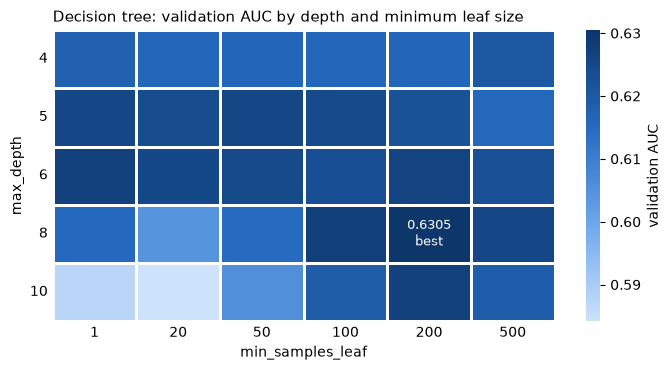

In [9]:
# One blue, light = low AUC, dark = high AUC
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def plot_auc_grid(grid: pd.DataFrame, title: str) -> None:
    """Heatmap of validation AUC over two hyperparameters; only the best cell is labelled."""
    best_row, best_col = grid.stack().idxmax()  # labels of the highest validation AUC
    row, col = grid.index.get_loc(best_row), grid.columns.get_loc(best_col)

    fig, ax = plt.subplots(figsize=(7, 3.8))
    sns.heatmap(grid, cmap=BLUES, linewidths=2, linecolor="white", ax=ax, cbar_kws={"label": "validation AUC"})
    ax.text(col + 0.5, row + 0.5, f"{grid.iloc[row, col]:.4f}\nbest", ha="center", va="center", color="white", fontsize=9)
    ax.set_title(title, loc="left", fontsize=11)
    ax.tick_params(length=0)  # no tick marks, labels only
    ax.yaxis.set_tick_params(rotation=0)
    plt.tight_layout()
    plt.show()


plot_auc_grid(leaf_results["val_auc"].unstack(), "Decision tree: validation AUC by depth and minimum leaf size")


Depths 8 and 10 overfit with small leaves, but recover once each leaf needs 100 to 200 patients: depth 10 goes from 0.587 to
0.627. The best tree (depth 8, `min_samples_leaf` 200) reaches 0.6305, only 0.003 above the best depth-only tree and
0.02 below the logistic regression (0.651). Tuning does not close the gap, so the single tree is not a candidate for the
service; it confirms that the next step is to combine many trees.


### 3.3 Random forest

Many trees, each trained on a random sample of patients and of columns, with their probabilities averaged. Depth and number
of trees are tuned first, then the minimum leaf size around the best depths.


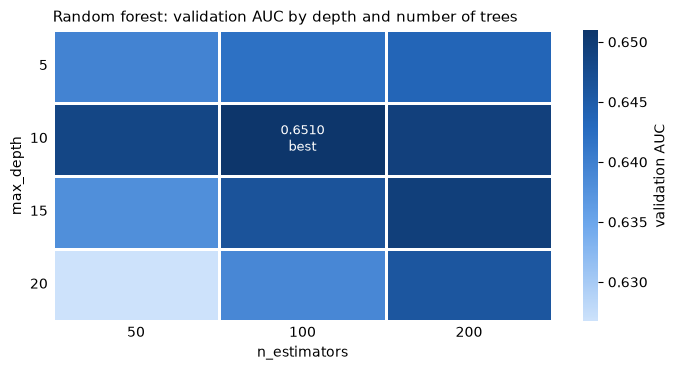

,max_depth,n_estimators,train_auc,val_auc
0,5,50,0.6665,0.6396
1,5,100,0.6698,0.6420
2,5,200,0.6722,0.6436
3,10,50,0.7809,0.6485
4,10,100,0.7927,0.6510
5,10,200,0.7951,0.6493
6,15,50,0.9428,0.6380
7,15,100,0.9525,0.6464
8,15,200,0.9565,0.6495
9,20,50,0.9951,0.6267


In [10]:
rf_depth_results = pd.DataFrame({
    (depth, n): evaluate(
        RandomForestClassifier(n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1),  # n_jobs=-1: all CPU cores
        FEATURES_ALL,
    )
    for depth in [5, 10, 15, 20]
    for n in [50, 100, 200]
}).T
rf_depth_results.index.names = ["max_depth", "n_estimators"]

plot_auc_grid(rf_depth_results["val_auc"].unstack(), "Random forest: validation AUC by depth and number of trees")
rf_depth_results.round(4).reset_index()



The forest beats the single tree clearly: 0.651 at depth 10 with 100 trees, against 0.6305 for the best tree, because
averaging many trees gives a much finer ranking of patients. More trees help most when the trees are deep: at depth 20,
going from 50 to 200 trees adds 0.019, since averaging cancels out the noise of each overfitted tree. Differences of about
0.002 (depth 10: 100 vs 200 trees) are random variation, not real improvements.


#### Minimum leaf size

With 200 trees fixed (more trees never hurt accuracy, they only cost time), the minimum leaf size is tested on depths 10,
15 and 20. Depth 5 is left out: it was clearly below the others.


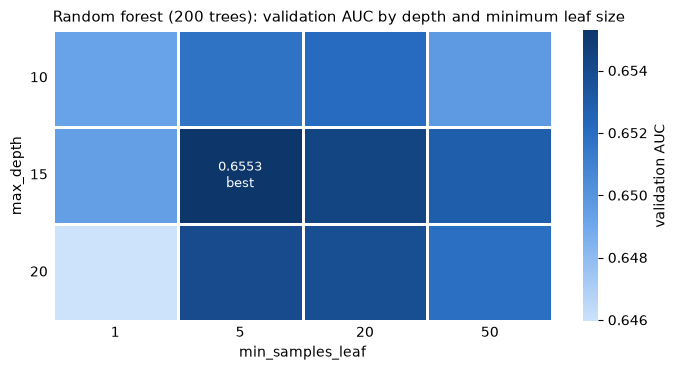

,max_depth,min_samples_leaf,train_auc,val_auc
0,10,1,0.7951,0.6493
1,10,5,0.7521,0.6517
2,10,20,0.7234,0.6521
3,10,50,0.7026,0.6497
4,15,1,0.9565,0.6495
5,15,5,0.8664,0.6553
6,15,20,0.7886,0.6544
7,15,50,0.7396,0.6529
8,20,1,0.9978,0.6460
9,20,5,0.9454,0.6540


In [11]:
rf_leaf_results = pd.DataFrame({
    (depth, leaf): evaluate(
        RandomForestClassifier(
            n_estimators=200, max_depth=depth, min_samples_leaf=leaf, random_state=1, n_jobs=-1
        ),
        FEATURES_ALL,
    )
    for depth in [10, 15, 20]
    for leaf in [1, 5, 20, 50]
}).T
rf_leaf_results.index.names = ["max_depth", "min_samples_leaf"]

plot_auc_grid(
    rf_leaf_results["val_auc"].unstack(),
    "Random forest (200 trees): validation AUC by depth and minimum leaf size",
)
rf_leaf_results.round(4).reset_index()


A minimum leaf of 5 to 20 patients helps every depth, most of all the deeper forests: depth 15 goes from 0.6495 to 0.6553
with leaves of at least 5. The best forest (depth 15, `min_samples_leaf` 5, 200 trees) reaches a validation AUC of 0.6553.
That is 0.0043 above the logistic regression (0.651), less than the 0.005 margin a more complex model should add to earn
its place. The final choice is made in section 4, after XGBoost.
